# Задача 3: Изображения значений из корня комплексного числа

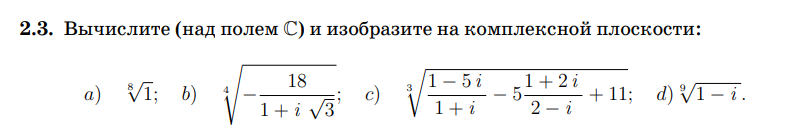


a) ⁸√1:
  k=0: z = 1.000000 + 0.000000i  (φ = 0.00°)
  k=1: z = 0.707107 + 0.707107i  (φ = 45.00°)
  k=2: z = 0.000000 + 1.000000i  (φ = 90.00°)
  k=3: z = -0.707107 + 0.707107i  (φ = 135.00°)
  k=4: z = -1.000000 + 0.000000i  (φ = 180.00°)
  k=5: z = -0.707107 + -0.707107i  (φ = -135.00°)
  k=6: z = -0.000000 + -1.000000i  (φ = -90.00°)
  k=7: z = 0.707107 + -0.707107i  (φ = -45.00°)

b) ⁴√(-18/(1+i√3)):  w = -4.5000 + 7.7942i, |w| = 9.0000
  k=0: z = 1.500000 + 0.866025i  (φ = 30.00°)
  k=1: z = -0.866025 + 1.500000i  (φ = 120.00°)
  k=2: z = -1.500000 + -0.866025i  (φ = -150.00°)
  k=3: z = 0.866025 + -1.500000i  (φ = -60.00°)

c) ³√(...):  w = 9.0000 + -8.0000i, |w| = 12.0416
  k=0: z = 2.225163 + -0.549759i  (φ = -13.88°)
  k=1: z = -0.636476 + 2.201928i  (φ = 106.12°)
  k=2: z = -1.588687 + -1.652168i  (φ = -133.88°)

d) ⁴√(1-i):  w = 1.0000 + -1.0000i, |w| = 1.4142
  k=0: z = 1.069554 + -0.212748i  (φ = -11.25°)
  k=1: z = 0.212748 + 1.069554i  (φ = 78.75°)
  k=2: z = -1.069554 

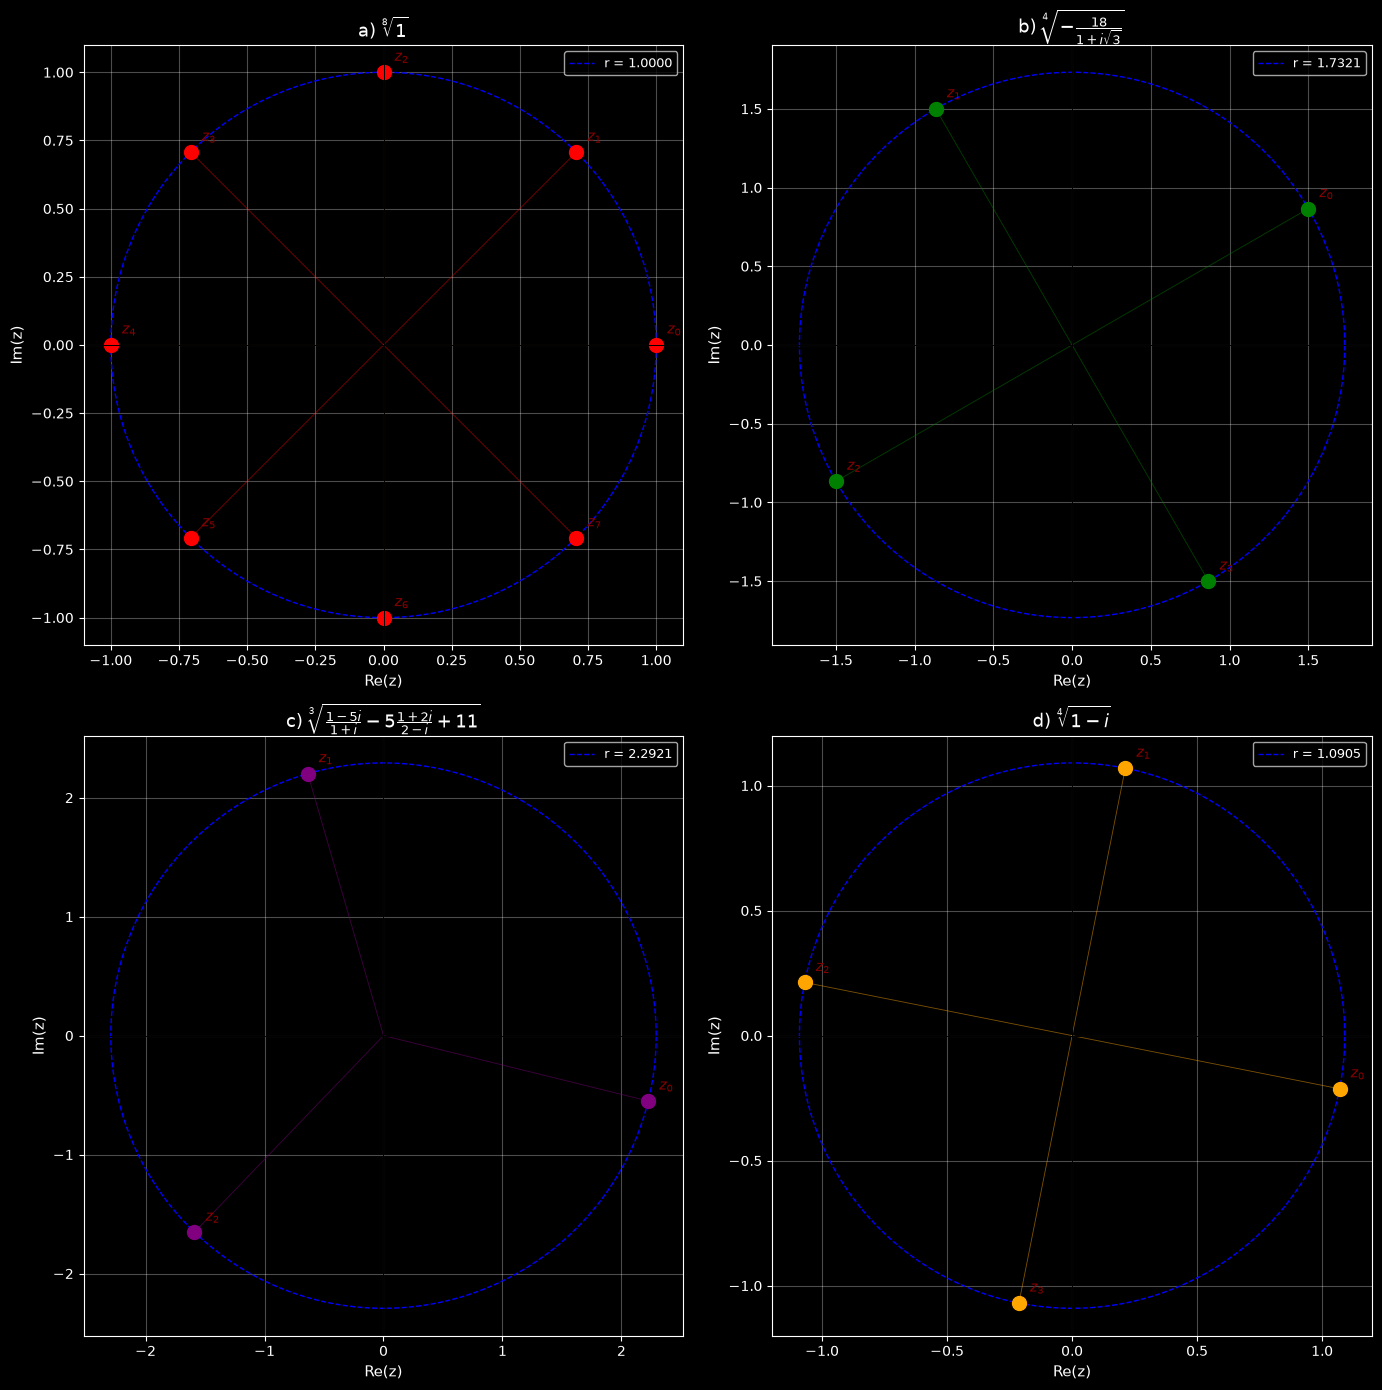

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def nth_roots(w, n):
    R = abs(w)
    psi = np.angle(w)
    r = R ** (1/n)
    roots = []
    for k in range(n):
        phi_k = (psi + 2 * np.pi * k) / n
        roots.append(r * np.exp(1j * phi_k))
    return roots, r

w_a = 1 + 0j
roots_a, r_a = nth_roots(w_a, 8)
print("a) ⁸√1:")
for k, z in enumerate(roots_a):
    print(f"  k={k}: z = {z.real:.6f} + {z.imag:.6f}i  (φ = {np.degrees(np.angle(z)):.2f}°)")


w_b = -18 / (1 + 1j * np.sqrt(3))
roots_b, r_b = nth_roots(w_b, 4)
print(f"\nb) ⁴√(-18/(1+i√3)):  w = {w_b.real:.4f} + {w_b.imag:.4f}i, |w| = {abs(w_b):.4f}")
for k, z in enumerate(roots_b):
    print(f"  k={k}: z = {z.real:.6f} + {z.imag:.6f}i  (φ = {np.degrees(np.angle(z)):.2f}°)")


term1 = (1 - 5j) / (1 + 1j)
term2 = 5 * (1 + 2j) / (2 - 1j)
w_c = term1 - term2 + 11
roots_c, r_c = nth_roots(w_c, 3)
print(f"\nc) ³√(...):  w = {w_c.real:.4f} + {w_c.imag:.4f}i, |w| = {abs(w_c):.4f}")
for k, z in enumerate(roots_c):
    print(f"  k={k}: z = {z.real:.6f} + {z.imag:.6f}i  (φ = {np.degrees(np.angle(z)):.2f}°)")


w_d = 1 - 1j
roots_d, r_d = nth_roots(w_d, 4)
print(f"\nd) ⁴√(1-i):  w = {w_d.real:.4f} + {w_d.imag:.4f}i, |w| = {abs(w_d):.4f}")
for k, z in enumerate(roots_d):
    print(f"  k={k}: z = {z.real:.6f} + {z.imag:.6f}i  (φ = {np.degrees(np.angle(z)):.2f}°)")


fig, axes = plt.subplots(2, 2, figsize=(14, 14))

def plot_roots(ax, roots, r, title, color='red'):
    theta = np.linspace(0, 2*np.pi, 300)
    ax.plot(r*np.cos(theta), r*np.sin(theta), 'b--', linewidth=1, label=f'r = {r:.4f}')
    for k, z in enumerate(roots):
        ax.plot(z.real, z.imag, 'o', color=color, markersize=10)
        ax.annotate(f'$z_{k}$', (z.real, z.imag),
                    textcoords="offset points", xytext=(8, 8),
                    fontsize=10, color='darkred')
        ax.plot([0, z.real], [0, z.imag], color=color, linewidth=0.6, alpha=0.5)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.axvline(0, color='black', linewidth=0.7)
    ax.set_xlabel('Re(z)', fontsize=11)
    ax.set_ylabel('Im(z)', fontsize=11)
    ax.set_title(title, fontsize=13)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)

plot_roots(axes[0,0], roots_a, r_a, r'a) $\sqrt[8]{1}$', color='red')
plot_roots(axes[0,1], roots_b, r_b, r'b) $\sqrt[4]{-\frac{18}{1+i\sqrt{3}}}$', color='green')
plot_roots(axes[1,0], roots_c, r_c, r'c) $\sqrt[3]{\frac{1-5i}{1+i} - 5\frac{1+2i}{2-i} + 11}$', color='purple')
plot_roots(axes[1,1], roots_d, r_d, r'd) $\sqrt[4]{1-i}$', color='orange')

plt.tight_layout()
plt.savefig('task_2_3.png', dpi=150)
plt.show()